# 09_01NN · Fashion-MNIST neural networks



## Learning objectives
- Explore and normalize images and labels.
- Understand network architecture, logits, and parameter counts.
- Train, validate, evaluate and diagnose a neural network.
- Investigate errors, image transformations and overfitting.

**Important:** Keep the test set for final evaluation, not hyperparameter selection. Optional model experiments at the end use validation data.

Source: https://www.tensorflow.org/tutorials


Install required packages. 
Tensorflow is a library used for neural networks. Keras is a neural network library within tensorflow.

In [43]:
#%pip install tensorflow 
# Note to myself!! Wait and check
# if everyone has working tensorflow installation
from __future__ import absolute_import, division, print_function, unicode_literals

# TensorFlow and tf.keras
import tensorflow as tf
from tensorflow import keras

# Helper libraries
import numpy as np
import matplotlib.pyplot as plt

Read in the data. The data is available from keras library.

In [44]:
fashion_mnist = keras.datasets.fashion_mnist

(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

Add class names (by default classes are only numbers).

In [45]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Check the dimension of the training set of images.

In [46]:
train_images.shape

(60000, 28, 28)

Check the length of the labels for the training set.

In [47]:
len(train_labels)

60000

Have a look at the labels of the training set.

In [48]:
train_labels

array([9, 0, 0, ..., 3, 0, 5], shape=(60000,), dtype=uint8)

Mini task: Check the dimentions of the test set of images.

Mini task: Check the lenght of the vector of labels for the testing set

Task: What is the number of training and test images, the image dimensions, and the number of distinct classes?
Why should the test data not be used for fitting or hyperparameter choices?



Preprocess the data. With mini tasks.

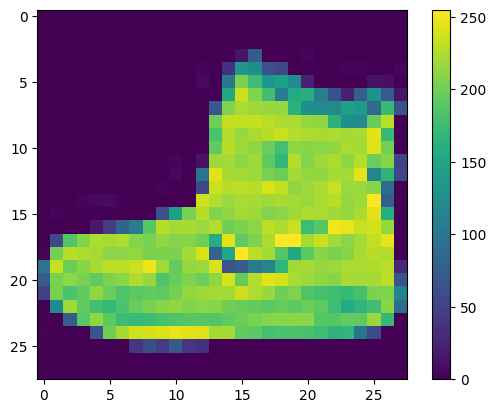

In [49]:
plt.figure()  # create new figure
plt.imshow(train_images[0]) # show the first image from the training set. How could you show the 10th image?
plt.colorbar() # add the colorbar to the plot. See what happens when you remove this line
plt.grid(False) # Do not show the grid on the plot. See what happens if you change False to True


Task:

Display image number 9 (the tenth image, since Python starts at zero) with its class label as the title. Try another index.  



Scale the values in the images to the range 0-1

In [50]:
train_images = train_images / 255.0

test_images = test_images / 255.0


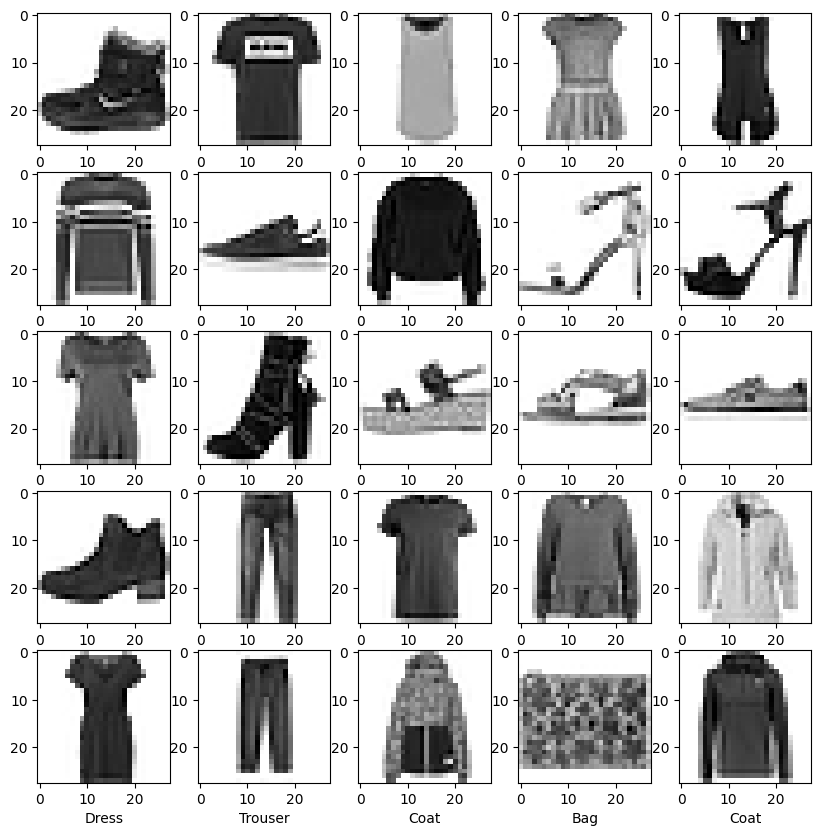

In [51]:
# Scaled images with mini tasks
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1) # split plot into 5 x 5 table. Use the i+1 place to plot the next image.
    plt.imshow(train_images[i], cmap=plt.cm.binary) # plt.cm.binary allows to show black-white image.
    #Check what happens if you uncomment the rest of the line
    plt.xlabel(class_names[train_labels[i]])
plt.show()

Task: Which clothes are most common?

Count how many training examples belong to each of the ten classes and draw a bar chart using the class names. Is the dataset balanced?


Hint: 'np.bincount'



Build the model. We are adding different layers to the network, which well be trained later on the training data set. The parameters of these layers will be learned during training. The first layer, Flatten, has no parameters to learn; it only reformats the data. What does each of the layers do? How does it look like? 

In [52]:
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(10)
])

Task: 

Use `model.summary()` to inspect the architecture. Find the total number of trainable parameters. How many parameters are in the first Dense layer (128 neurons), including biases?

The Flatten layer produces 28 × 28 inputs. Each Dense neuron has one bias. (Bias is like an intercept in the logistic regression)


Task: Follow one neuron

Compute the output of a ReLU neuron for `x=[2,3]`, `w=[0.5,-1]`, `b=2`. Change the second weight to `-0.5`. What changes?

Hint: You can Use `np.dot(x,w)` and `max(0,z)`.



Setting more parameters of the model - what exactly we would like to optimize.

In [53]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

Task: Output scores versus probabilities

The final Dense layer has no softmax. Inspect the untrained model output for `train_images[:1]`: do the 10 values necessarily sum to 1?

Apply `tf.nn.softmax` to logits to obtain probabilities.


Train the model
Training the neural network model requires the following steps:

1. Feed the training data to the model. In this example, the training data is in the train_images and train_labels arrays.
2. The model learns to associate images and labels.
3. You ask the model to make predictions about a test set—in this example, the test_images array.
4. Verify that the predictions match the labels from the test_labels array.

Feed the data into the model. Train for 10 epochs, while reserving 15% of the training data for validation. Observe how learning progresses.

In [54]:
history = model.fit(train_images, train_labels, epochs=10, validation_split=0.15, batch_size=128)

Epoch 1/10
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7883 - loss: 0.6056 - val_accuracy: 0.8439 - val_loss: 0.4354
Epoch 2/10
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8545 - loss: 0.4107 - val_accuracy: 0.8631 - val_loss: 0.3885
Epoch 3/10
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8679 - loss: 0.3697 - val_accuracy: 0.8658 - val_loss: 0.3671
Epoch 4/10
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8762 - loss: 0.3420 - val_accuracy: 0.8759 - val_loss: 0.3464
Epoch 5/10
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8840 - loss: 0.3174 - val_accuracy: 0.8753 - val_loss: 0.3534
Epoch 6/10
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8902 - loss: 0.3013 - val_accuracy: 0.8579 - val_loss: 0.3914
Epoch 7/10
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8939 - loss: 0.2900 - val_accuracy: 0.8807 - val_loss: 0.3315
Epoch 8/10
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8984 - loss: 0.2750 - val_accuracy: 0.

Task: Plot learning curves

The training call stores its results in `history`. Plot training and validation accuracy against epochs, and compare them. Are the two curves close?


A Keras History object has the dictionary `history.history`.



Task: Detect overfitting

Plot **training loss** and **validation loss**. Mark the epoch with the lowest validation loss. **Discuss:** Would training for 100 epochs necessarily improve validation performance?

Use `np.argmin(history.history["val_loss"])`.



Evaluate accuracy

In [55]:
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

print('\nTest accuracy:', test_acc)

313/313 - 0s - 1ms/step - accuracy: 0.8774 - loss: 0.3426

Test accuracy: 0.8773999810218811


Task: Calculate accuracy by hand

Get predicted classes for the **first 100 test images**, compare them to their true labels, and calculate accuracy using NumPy. Compare it with `model.evaluate` on the same 100 images.

Hint:
Predicted class = index of the largest logit (`axis=1`).
See also np.argmax



Make predictions (the final model layer gives **logits**; softmax converts them to probabilities).

In [56]:
probability_model = tf.keras.Sequential([model,
                                         tf.keras.layers.Softmax()])

In [57]:
predictions = probability_model.predict(test_images)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [58]:
predictions[0]

array([2.7567262e-06, 1.2090632e-08, 1.6441408e-06, 9.6516806e-07,
       1.0863107e-06, 4.1429594e-04, 8.6328532e-07, 1.1906990e-02,
       6.8081157e-08, 9.8767126e-01], dtype=float32)

A prediction is an array of 10 numbers. They represent the model's "confidence" that the image corresponds to each of the 10 different articles of clothing. You can see which label has the highest confidence value:

In [59]:
print(np.argmax(predictions[0]))

9


In [60]:
print(test_labels[0])

9


Task: Confident but wrong?

Find the most confident incorrect prediction among the first 500 test images. Display that image and print its true label, predicted label, and predicted probability.

Hint:

Find incorrect predictions with `np.flatnonzero`, then sort/select by confidence.



324


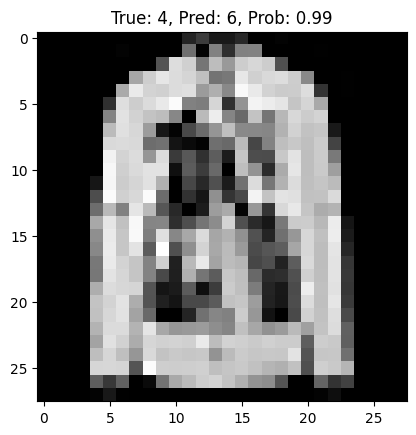

Graph this to look at the full set of 10 class predictions. It is for visualization only. 

In [64]:
def plot_image(i, predictions_array, true_label, img):
  predictions_array, true_label, img = predictions_array, true_label[i], img[i]
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])

  plt.imshow(img, cmap=plt.cm.binary)

  predicted_label = np.argmax(predictions_array)
  if predicted_label == true_label:
    color = 'blue'
  else:
    color = 'red'

  plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                100*np.max(predictions_array),
                                class_names[true_label]),
                                color=color)

def plot_value_array(i, predictions_array, true_label):
  predictions_array, true_label = predictions_array, true_label[i]
  plt.grid(False)
  plt.xticks(range(10))
  plt.yticks([])
  thisplot = plt.bar(range(10), predictions_array, color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(predictions_array)

  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')

Verify predictions

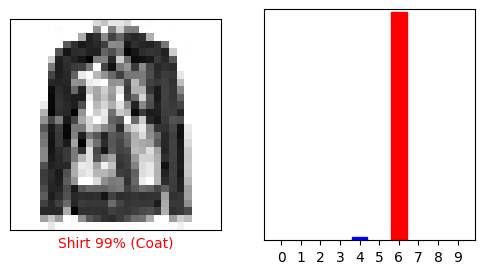

In [67]:
i = 324
plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plot_image(i, predictions[i], test_labels, test_images)
plt.subplot(1,2,2)
plot_value_array(i, predictions[i],  test_labels)
plt.show()

Let's plot several images with their predictions. 

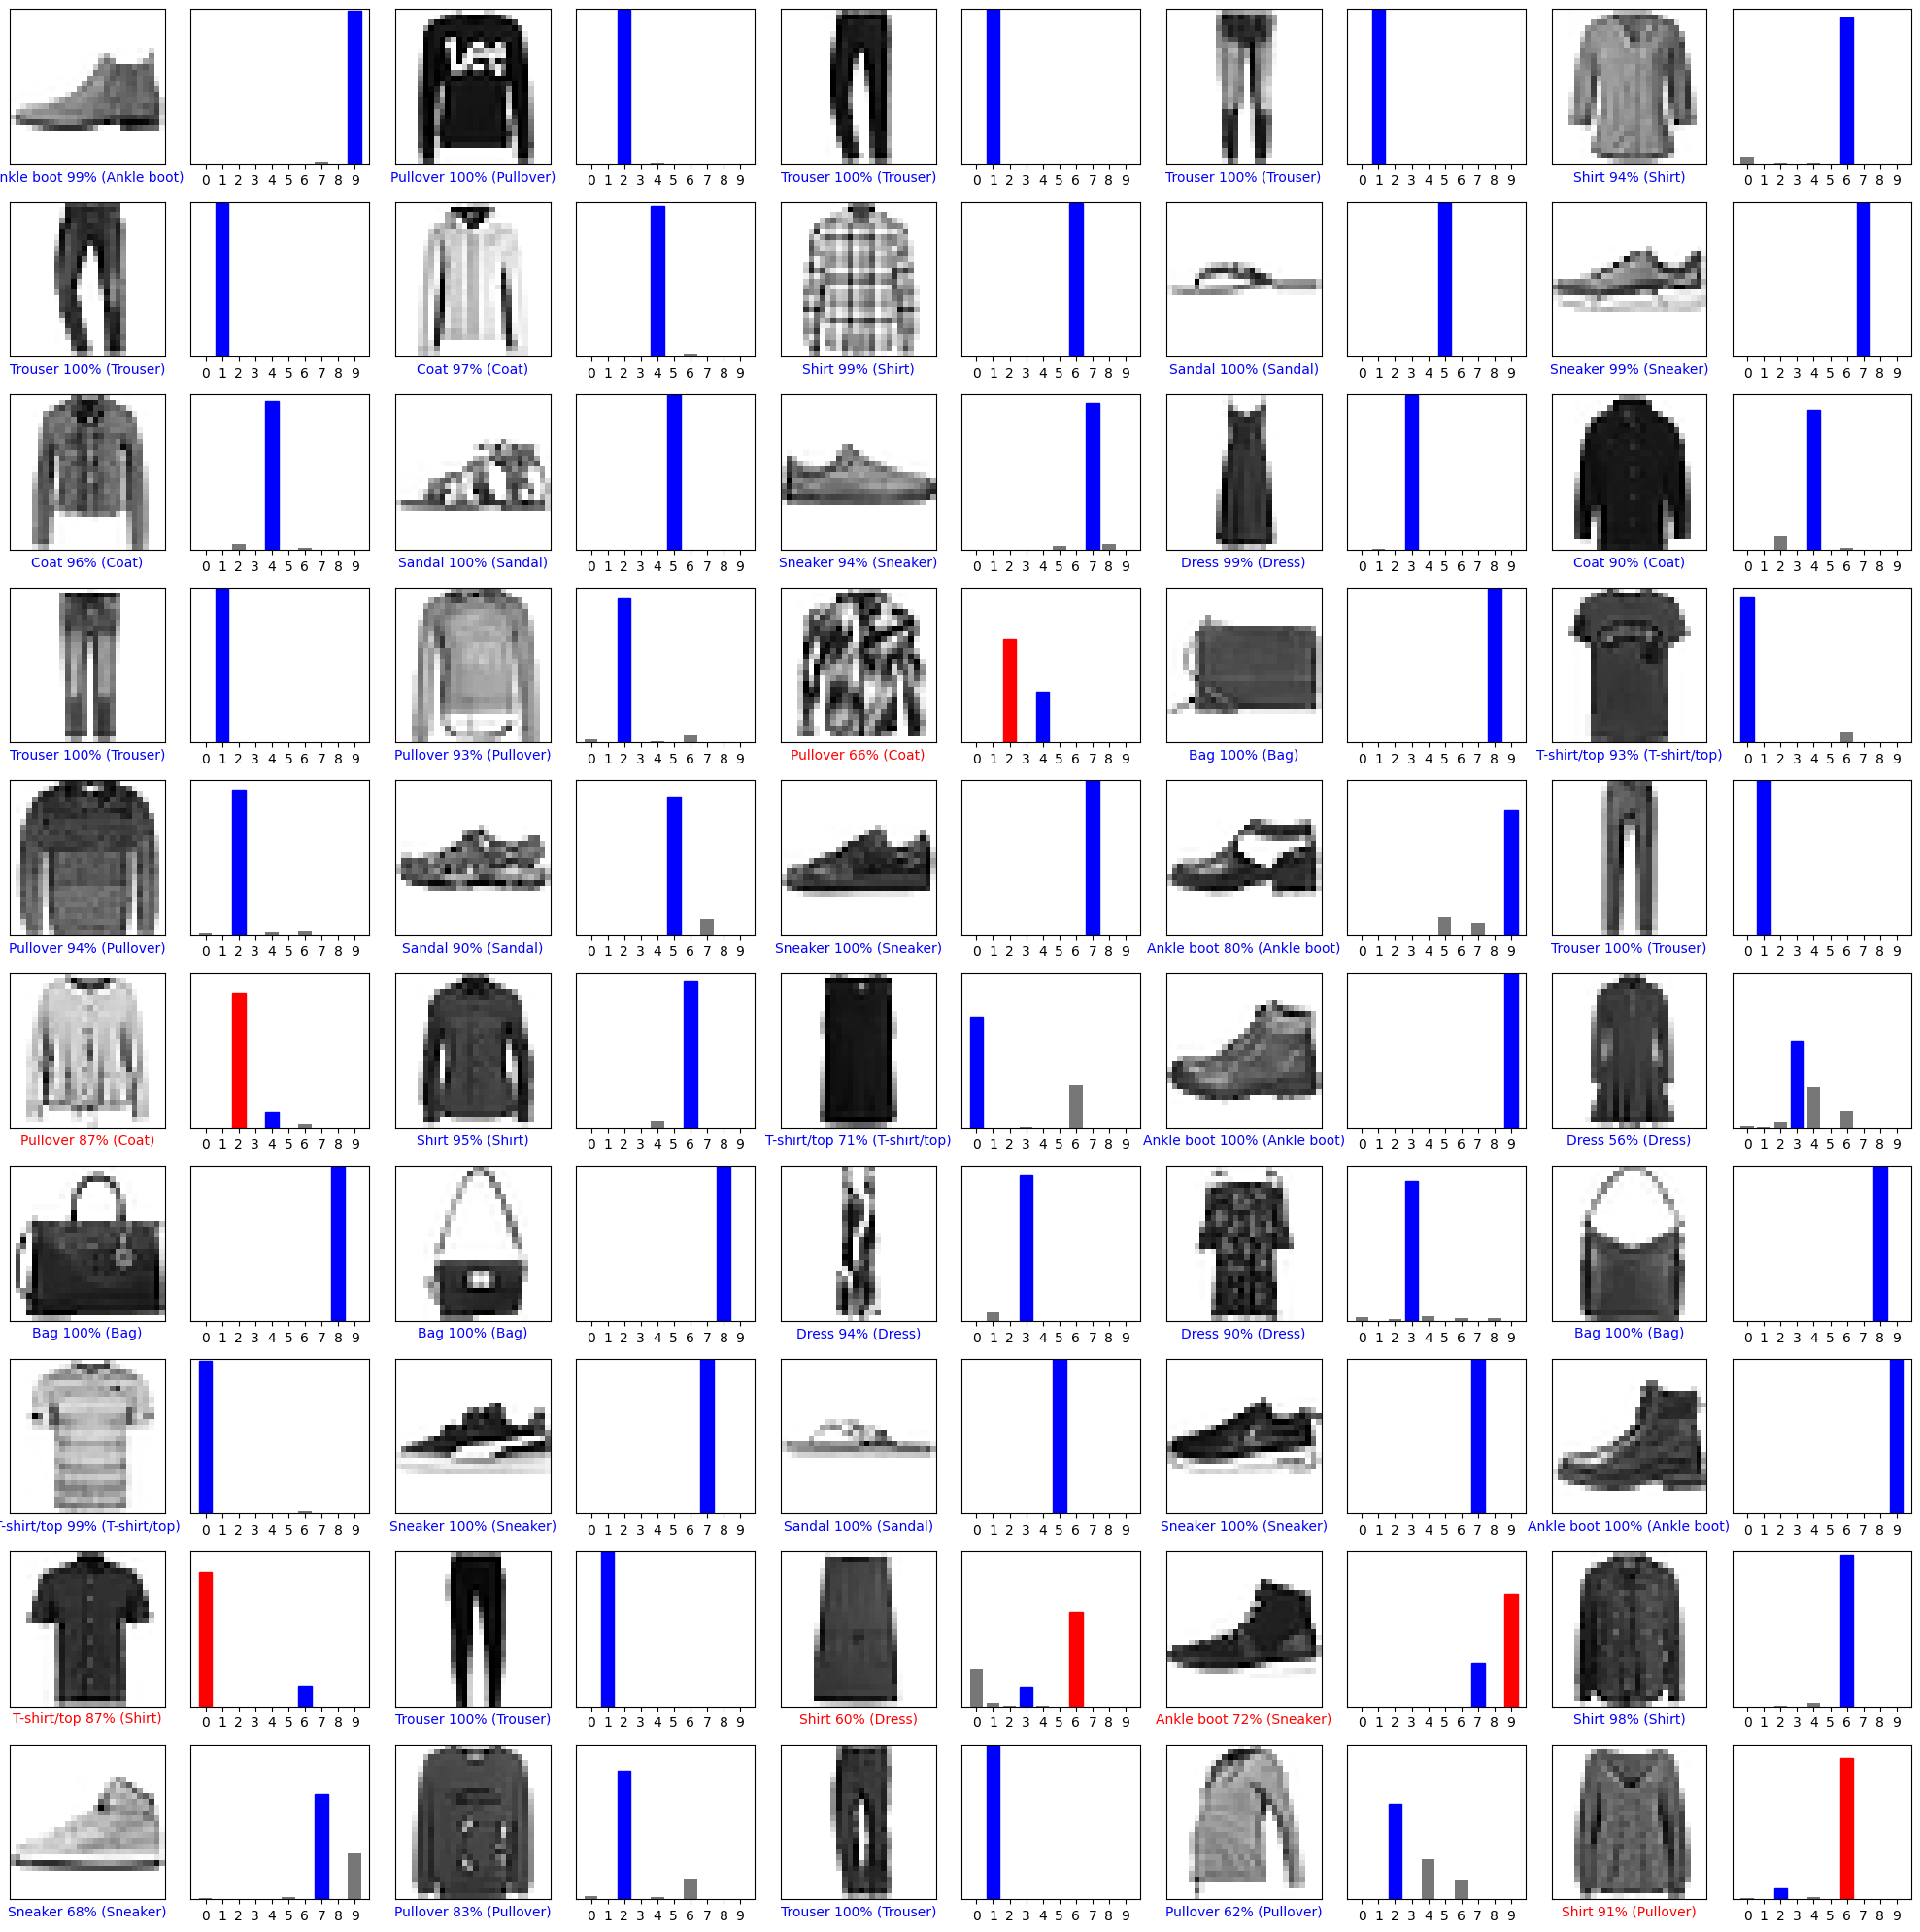

In [68]:
# Plot the first X test images, their predicted labels, and the true labels.
# Color correct predictions in blue and incorrect predictions in red.
num_rows = 10
num_cols = 5
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_image(i, predictions[i], test_labels, test_images)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_value_array(i, predictions[i], test_labels)
plt.tight_layout()
plt.show()

Task: Confusion matrix 
Build a `10 × 10` confusion matrix for the test set using NumPy. Which two categories are often confused?


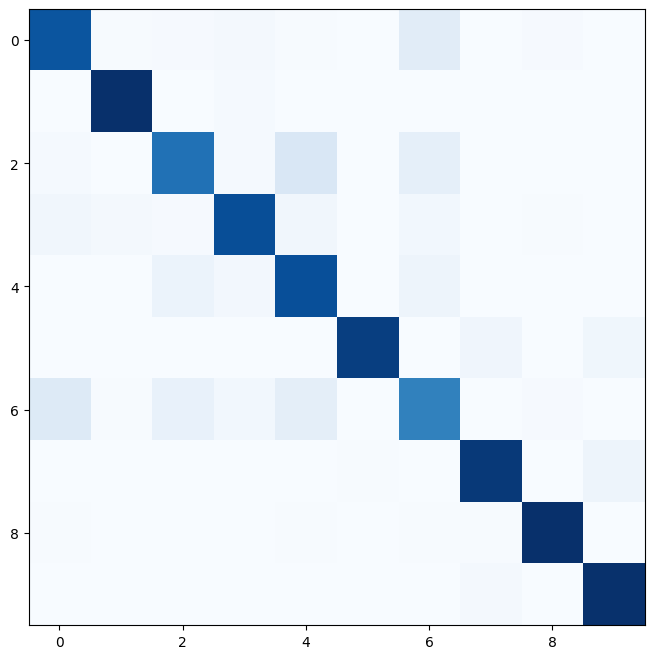

Task Class-by-class accuracy

Calculate accuracy separately for each true clothing class. Which category is hardest for your network?

Hint:

Correct examples of class k are on the diagonal; all class-k examples form row k.



use the trained model to make a prediction about a single image.

In [ ]:
# Grab an image from the test dataset.
n = 25
img = test_images[n]

print(img.shape)

(28, 28)


In [ ]:
# Add the image to a batch where it's the only member.
img = (np.expand_dims(img,0))

print(img.shape)

(1, 28, 28)


In [ ]:
predictions_single = probability_model.predict(img)

print(predictions_single)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
[[1.00543583e-03 3.01543332e-05 7.32598364e-01 6.31030183e-04
  1.76377550e-01 1.72621603e-05 8.92369822e-02 1.61585940e-05
  7.62127529e-05 1.08559625e-05]]


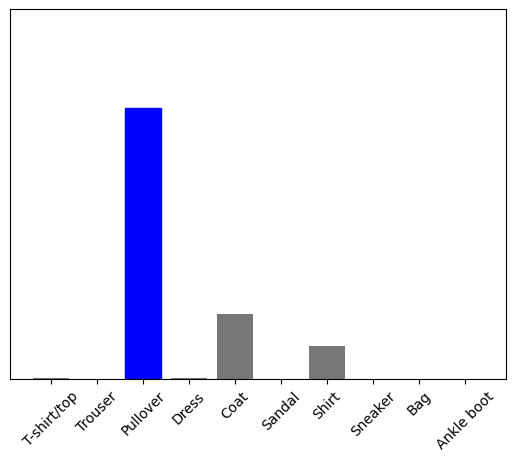

In [ ]:
plot_value_array(1, predictions_single[0], test_labels)
_ = plt.xticks(range(10), class_names, rotation=45)

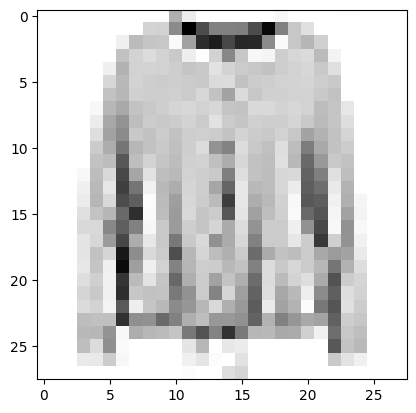

In [ ]:
plt.imshow(test_images[n], cmap=plt.cm.binary)
plt.show()

Task: Change the image, change the prediction

Choose a test image and compare the predicted probabilities before and after a horizontal flip. Display both images. Should a clothing classifier always be invariant to reflection?

Hint:
Try `np.fliplr` and use `model.predict` on a batch of two images.



Task: What if the image becomes noisy?

Add Gaussian noise to one image, clip the pixels to `[0,1]`, and compare predictions for the original and noisy images. Try noise levels `0.1`, `0.3`, and `0.5`. How does confidence change?
Hint:
Use `rng.normal` to add noise and `np.clip` to keep values between 0 and 1.



Task: Model laboratory 

Train a with only one hidden Dense layer (32 neurons) for 5 epochs. Compare its validation accuracy and parameter count with the original network. Which model will have more parameters?

You can try also different models, with different numbers of layers. 

Task: Early stopping (optional)

Train a small network with `EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)`. Allow up to 20 epochs. How many epochs actually ran?

Hint:

Use `keras.callbacks.EarlyStopping` and look at `len(history.history["loss"])`.



## Further practice
Try another dataset: https://keras.io/api/datasets/

